# VOC数据集

In [1]:
import torch

In [2]:
from dataset import VOCDetectionForYOLO

IMG_SIZE = 448  # resnet backbone决定的
S = 7

train_data = VOCDetectionForYOLO('train', image_size=IMG_SIZE, n_grid=S)

{'annotation': {'folder': 'VOC2012', 'filename': '2008_000008.jpg', 'source': {'database': 'The VOC2008 Database', 'annotation': 'PASCAL VOC2008', 'image': 'flickr'}, 'size': {'width': '500', 'height': '442', 'depth': '3'}, 'segmented': '0', 'object': [{'name': 'horse', 'pose': 'Left', 'truncated': '0', 'occluded': '1', 'bndbox': {'xmin': '53', 'ymin': '87', 'xmax': '471', 'ymax': '420'}, 'difficult': '0'}, {'name': 'person', 'pose': 'Unspecified', 'truncated': '1', 'occluded': '0', 'bndbox': {'xmin': '158', 'ymin': '44', 'xmax': '289', 'ymax': '167'}, 'difficult': '0'}]}}
(500, 442)


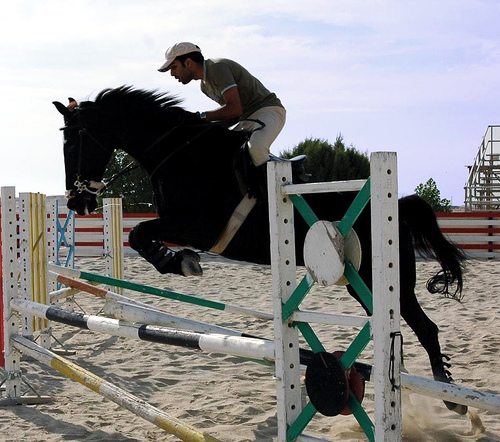

In [3]:
img, label = train_data.voc[0]
print(label)
print(img.size)
img

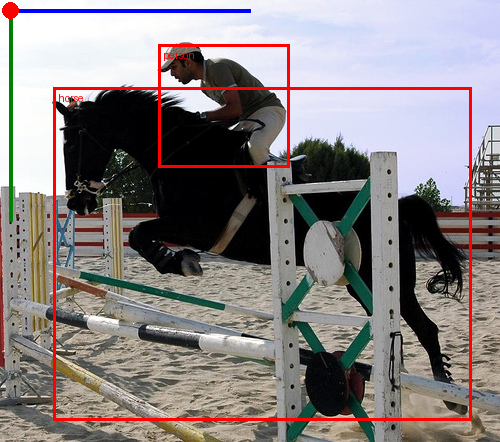

In [4]:
from PIL import ImageDraw

# 画框工具
draw = ImageDraw.Draw(img)

# 遍历每个object
for obj in label['annotation']['object']:
    box = obj['bndbox']
    draw.rectangle(
        [int(box['xmin']), int(box['ymin']), int(box['xmax']), int(box['ymax'])],
        outline='red',
        width=3
    )
    draw.text(
        [int(box['xmin']) + 5, int(box['ymin']) + 5],
        text=obj['name'],
        fill='red'
    )

offset = 10
draw.line([(offset, offset), (img.width / 2, offset)], fill='blue', width=4)     # x 轴
draw.line([(offset, offset), (offset, img.height / 2)], fill='green', width=4)    # y 轴
draw.ellipse([(offset-8, offset-8), (offset+8, offset+8)], fill='red')      # 原点

img

In [5]:
img, label = train_data[0]
print(label.shape)
print(img.shape)

torch.Size([7, 7, 30])
torch.Size([3, 448, 448])


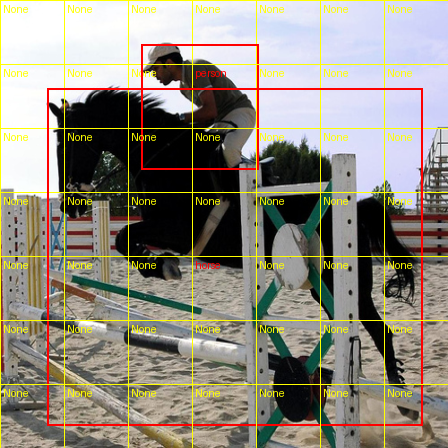

In [6]:
from PIL import ImageDraw
import torchvision.transforms as T

to_pil = T.ToPILImage()
img = to_pil(img)
draw = ImageDraw.Draw(img)

W, H = img.size
cell_w = W / S
cell_h = H / S

C = train_data.n_classes

for i in range(S):
    for j in range(S):
        cell = label[i, j]

        # 只取第一个 bbox (b=0)
        offset = 0
        conf = cell[offset + 4].item()
        if conf < 1.:
            draw.text((j*cell_w + 3, i*cell_h + 3), text='None', fill='yellow')
        else:
            # 取类别概率最大那个
            class_probs = cell[-C:]
            class_id = torch.argmax(class_probs).item()
            responsible_cls = train_data.idx_to_class[class_id]

            # bbox坐标（已归一化）
            x_center = cell[offset + 0].item()
            y_center = cell[offset + 1].item()
            bw = cell[offset + 2].item()
            bh = cell[offset + 3].item()

            # 转成图像像素坐标
            xmin = (j + x_center) * cell_w - bw * W / 2
            ymin = (i + y_center) * cell_h - bh * H / 2
            xmax = (j + x_center) * cell_w + bw * W / 2
            ymax = (i + y_center) * cell_h + bh * H / 2

            # 画bbox
            draw.rectangle([xmin, ymin, xmax, ymax], outline='red', width=2)
            draw.text((j*cell_w + 3, i*cell_h + 3), responsible_cls, fill='red')

        # 画格子边界
        draw.rectangle([j*cell_w, i*cell_h, (j+1)*cell_w, (i+1)*cell_h], outline='yellow', width=1)

        # 在格子左上角写负责类别或None
        
img

# Train

In [7]:
from model import YOLOv1

batch_size = 256
num_epoch = 100
IMG_SIZE = 224  # resnet backbone决定的
S = 7


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_data = VOCDetectionForYOLO('train', image_size=IMG_SIZE, n_grid=S)
dataloader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=8)
model = YOLOv1(S, train_data.n_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)

for epoch in range(num_epoch):
    for x, label in dataloader:
        x = x.to(device)
        label = label.to(device)

        pred = model(x)
        loss = model.cal_loss(pred, label)
        
        optimizer.zero_grad()  # 梯度清零
        loss.backward()  # 损失回传
        # torch.nn.utils.clip_grad_norm_(model.parameters(),1.)  # 梯度裁剪
        optimizer.step()    

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch + 1}/{num_epoch}, Loss: {loss.item():.4f}')

Epoch 1/100, Loss: 1341.9761
Epoch 10/100, Loss: 723.9035
Epoch 20/100, Loss: 393.4932
Epoch 30/100, Loss: 227.3543
Epoch 40/100, Loss: 244.5963
Epoch 50/100, Loss: 179.6477
Epoch 60/100, Loss: 169.0274
Epoch 70/100, Loss: 137.5300
Epoch 80/100, Loss: 152.1725
Epoch 90/100, Loss: 114.0136
Epoch 100/100, Loss: 89.2891


# eval

In [8]:
# 绘制目标框
def draw_objects(draw,img,row,col,output_boxes,objname): # output_boxes是某grid下的1个bbox
    grid_size=IMG_SIZE/S
    
    # normal coodinates
    cx,cy=grid_size*(col+output_boxes[0]),grid_size*(row+output_boxes[1])
    w,h=output_boxes[2]*IMG_SIZE,output_boxes[3]*IMG_SIZE
    xmin,ymin,xmax,ymax=cx-w/2,cy-h/2,cx+w/2,cy+h/2
    
    # 缩放到原图坐标
    x_scale=img.width/IMG_SIZE
    y_scale=img.height/IMG_SIZE
    cx,cy=cx*x_scale,cy*y_scale
    xmin,ymin,xmax,ymax=xmin*x_scale,ymin*y_scale,xmax*x_scale,ymax*y_scale
    
    draw.circle((cx,cy),fill='red',radius=5)
    draw.rectangle((xmin,ymin,xmax,ymax),outline='red')
    draw.text((xmin+5,ymin+5),objname,fill='red')

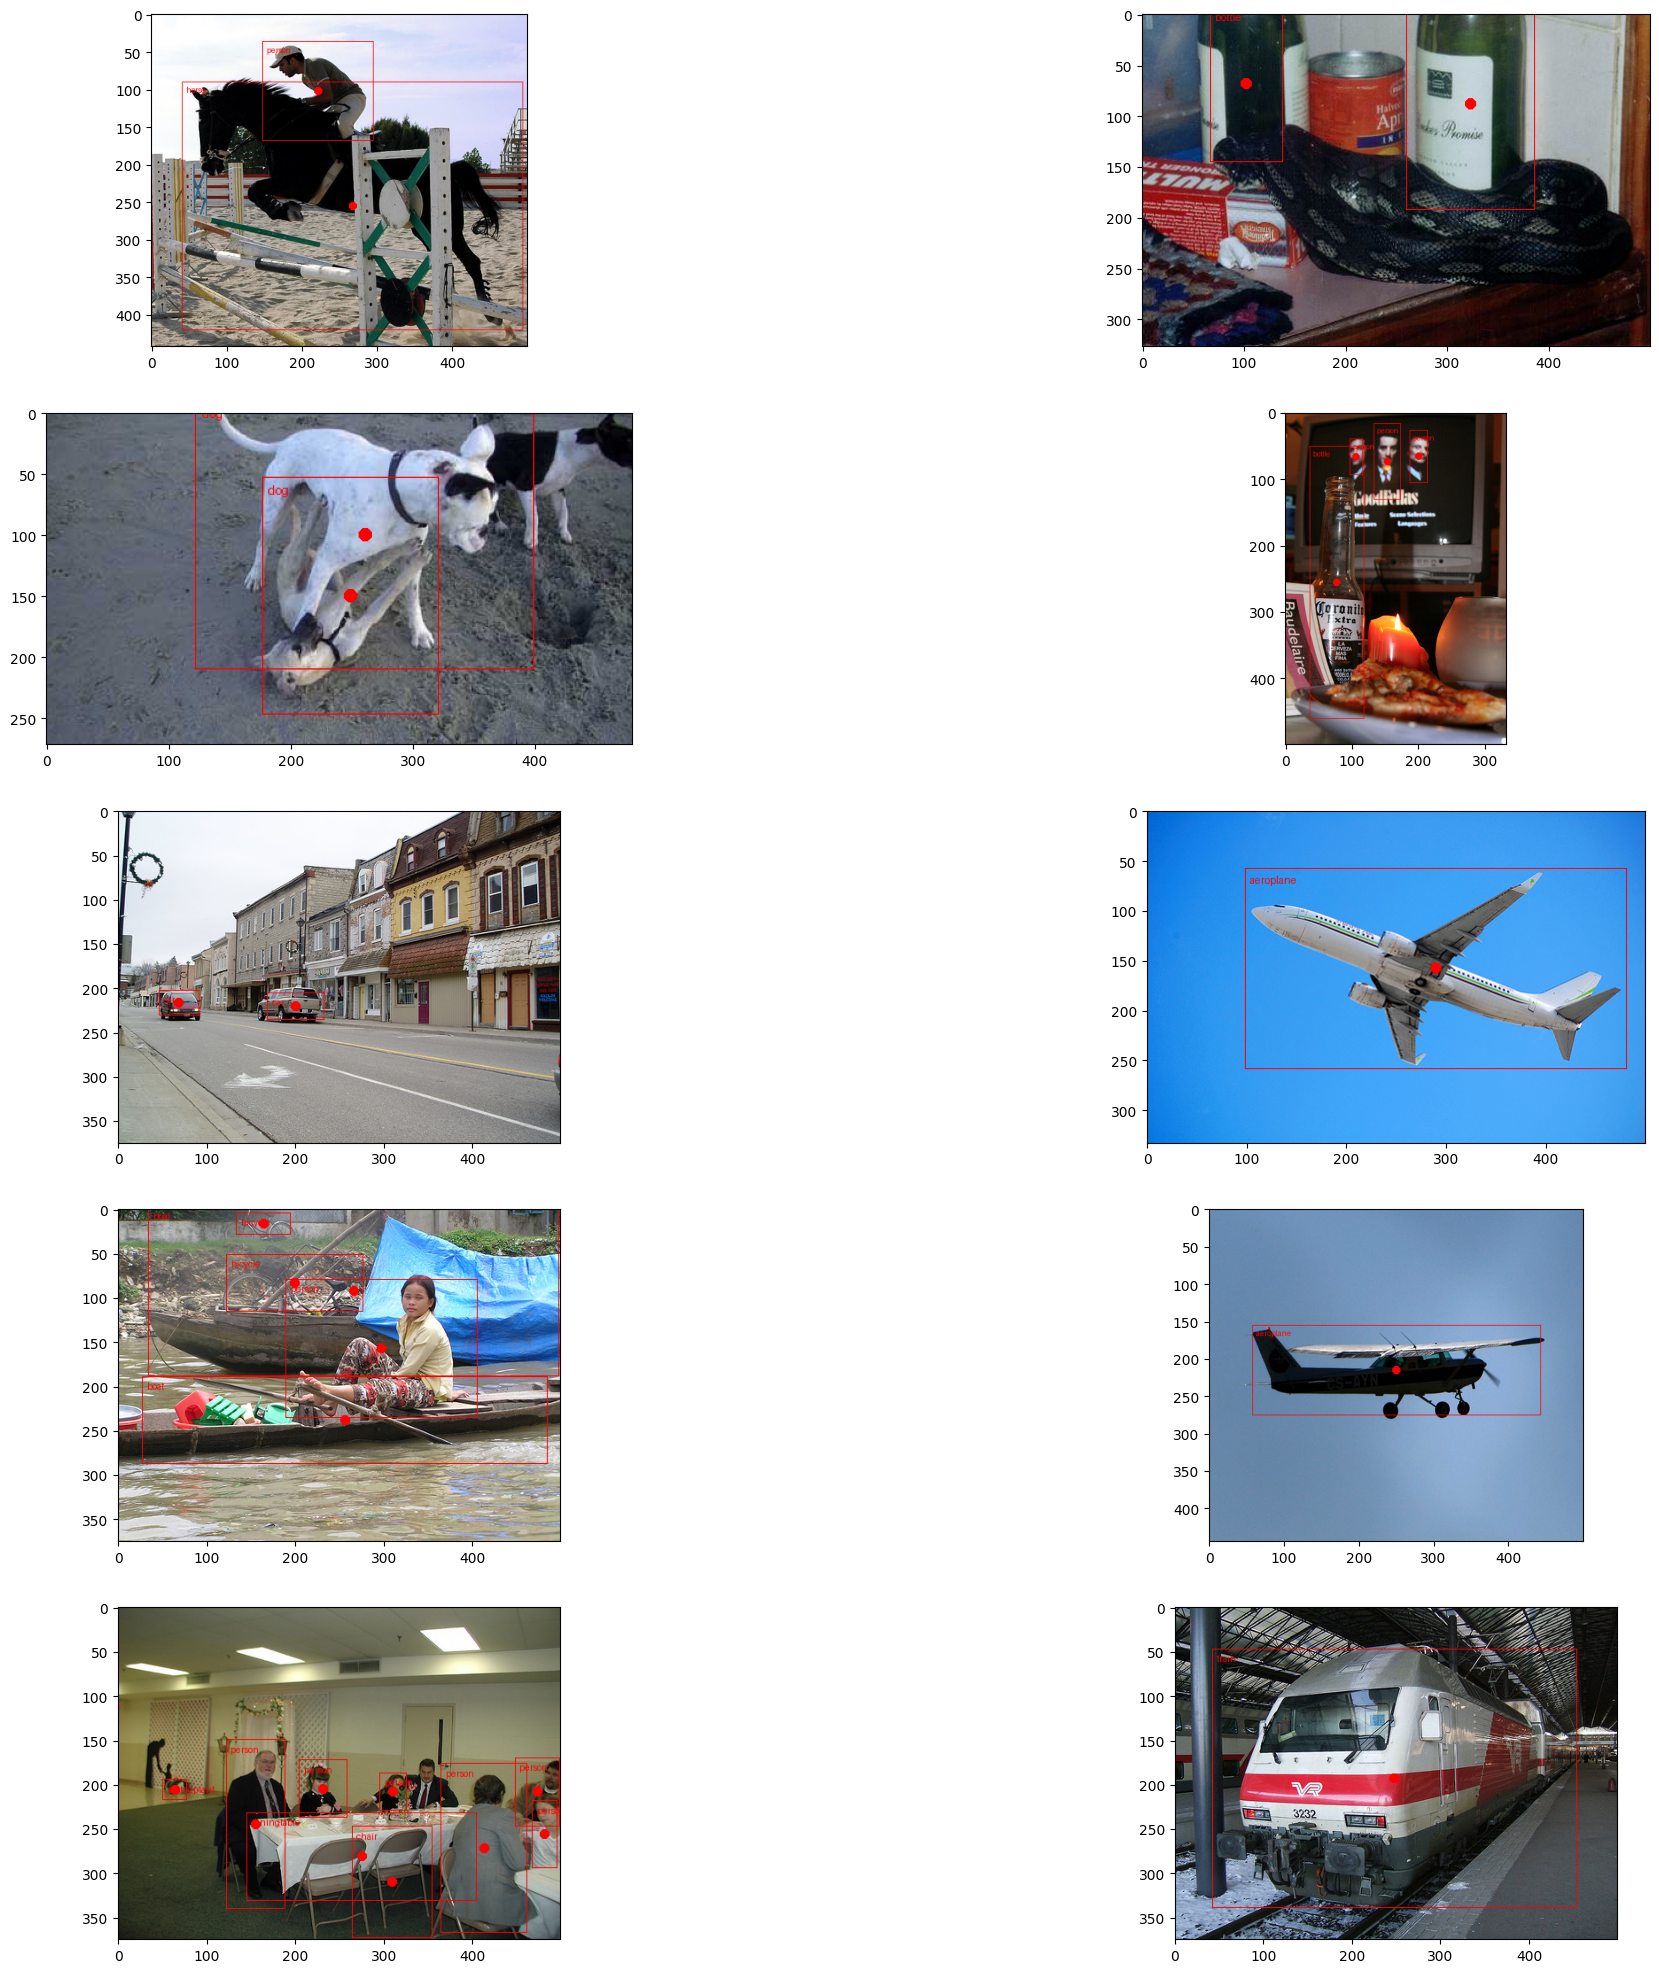

In [11]:
import matplotlib.pyplot as plt

val_data = VOCDetectionForYOLO('val', image_size=IMG_SIZE, n_grid=S)

model.eval()
plt.figure(figsize=(25,25))
for i in range(10):
    plt.subplot(5,2,i+1)
    x, y = train_data[i] # (3,224,224)
    img, _ = train_data.voc[i]  # 原图

    draw=ImageDraw.Draw(img)

    C_THREADHOLD=0.5

    output=model(x.unsqueeze(0).to(device))[0]
    for row in range(S):
        for col in range(S):
            objname = train_data.idx_to_class[output[row,col,10:].argmax().item()]
            if max(output[row,col,4], output[row,col,9]) < C_THREADHOLD:
                continue
            if output[row,col,4] > output[row,col,9]:
                draw_objects(draw,img,row,col,output[row,col,:5],objname)
            else:
                draw_objects(draw,img,row,col,output[row,col,5:10],objname)
    plt.imshow(img)